# Projeto Integrador de Mineração de Dados (2COP024 - UEL)
**Universidade Estadual de Londrina — Ciência da Computação / Ciência de Dados e IA**

---

### Pergunta de Pesquisa:
> **“É possível prever se uma avaliação de livro da Amazon será negativa com base no texto da resenha?”**

---

### 1. Contexto, Formulação do Problema e Dados

#### 1.1 Contexto e Justificativa de Negócio
No comércio eletrônico de livros, o volume diário de avaliações torna inviável a leitura manual de cada comentário. Identificar proativamente avaliações **negativas** (insatisfação, problemas com conteúdo, encadernação defeituosa ou expectativa frustrada) permite:
- Priorizar atendimento ao cliente e suporte pós-venda;
- Identificar falhas editoriais, defeitos de impressão ou edições corrompidas;
- Proteger a reputação da loja e mitigar o abandono de clientes (*churn*).

Neste projeto, a tarefa de mineração de dados é formulada como uma **classificação binária de texto supervisionada**.

#### 1.2 Origem, Proveniência e Amostragem dos Dados
Os dados provêm do repositório acadêmico oficial **Amazon Reviews 2023** (McAuley Lab / Universidade da Califórnia em San Diego - UCSD), especificamente da categoria `Books`. O arquivo bruto populacional contém aproximadamente 29,5 milhões de registros (~20,1 GB).

Conforme documentado no notebook de engenharia de dados deste repositório (`extrair_amostra_20k_amazon_books.ipynb`), a amostra foi extraída por streaming direto via protocolo HTTP com **Algoritmo de Reservatório Bounded** (amostra de 20.000 avaliações com semente determinística `20261109`). O arquivo gerado foi validado e persistido com hash criptográfico SHA-256 (`outputs/books_reviews_sample_20k_seed_20261109_metadata.json`), garantindo total rastreabilidade.

#### 1.3 Dicionário de Dados das Colunas Reais
| Coluna | Tipo Original | Papel na Modelagem | Descrição |
| :--- | :--- | :--- | :--- |
| `rating` | `float64` | Definição da Variável-Alvo | Nota atribuída pelo usuário (1.0 a 5.0 estrelas). |
| `title` | `object` (string) | Atributo Preditivo (Texto) | Título síntese da avaliação (concatenado ao corpo). |
| `text` | `object` (string) | Atributo Preditivo (Texto) | Conteúdo textual completo da resenha. |
| `parent_asin` | `object` (string) | Metadado / Identificador | Código identificador do livro na Amazon. |
| `user_id` | `object` (string) | Metadado / Identificador | Identificador anônimo do avaliador. |
| `timestamp` | `int64` | Metadado Temporal | Carimbo de data/hora (ms Unix) da postagem. |
| `verified_purchase` | `bool` | Metadado Transacional | Indica se a compra foi verificada na Amazon. |
| `helpful_vote` | `int64` | Metadado Social | Quantidade de votos de utilidade recebidos. |

#### 1.4 Limitações Conhecidas da Amostra
- **Viés de Amostragem:** A amostragem foi executada sobre os primeiros ~10% das linhas do arquivo da Amazon para preservar banda de rede e tempo de execução; portanto, representa esse trecho inicial percorrido.
- **Desbalanceamento Severo:** Plataformas de livros apresentam forte assimetria positiva (mais de 90% das notas são 4 ou 5 estrelas).
- **Subjetividade Textual:** Críticas literárias contêm sarcasmo, ironia e resumos de enredos trágicos que desafiam analisadores puramente léxicos.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configurações visuais e determinísticas
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Caminho do dataset gerado
CSV_PATH = Path("outputs/books_reviews_sample_20k_seed_20261109.csv")
assert CSV_PATH.exists(), f"Arquivo CSV não encontrado em: {CSV_PATH}"

# Carregamento da amostra
df_raw = pd.read_csv(CSV_PATH)
print("Ambiente inicializado e base carregada:")
print(f"  - Registros carregados: {df_raw.shape[0]:,}")
print(f"  - Colunas encontradas:  {list(df_raw.columns)}")


Ambiente inicializado e base carregada:
  - Registros carregados: 20,000
  - Colunas encontradas:  ['rating', 'title', 'text', 'parent_asin', 'user_id', 'timestamp', 'verified_purchase', 'helpful_vote']


### 2. Definição da Variável-Alvo (`is_negative`)

A nota da avaliação (`rating`) é dada em uma escala discreta de 1.0 a 5.0 estrelas. Para responder com clareza à pergunta de pesquisa, convertemos o problema em uma **classificação binária polarizada**:

- **Notas 1.0 e 2.0 $\rightarrow$ Classe 1 (Avaliação Negativa):** Representa o cliente insatisfeito, com problemas de produto ou forte decepção.
- **Notas 4.0 e 5.0 $\rightarrow$ Classe 0 (Avaliação Positiva):** Representa o cliente satisfeito ou entusiasmado.
- **Nota 3.0 $\rightarrow$ Excluída da classificação binária:** Avaliações de 3 estrelas são neutras ou mistas (reúnem elogios e ressalvas). Manter notas neutras em uma classificação binária introduz fronteiras cinzentas e ruído artificial no aprendizado supervisionado de sentimento.

A convenção **Negativa = 1** é mantida com rigor em todo o código, tabelas, gráficos e métricas.


In [2]:
# Distribuição original das notas
print("Distribuição das Notas Originais na Amostra de 20.000 avaliações:")
for star, count in df_raw['rating'].value_counts().sort_index().items():
    print(f"  - {star:.1f} estrelas: {count:>6,} ({count/len(df_raw)*100:5.2f}%)")

# Aplicação da regra de binarização e exclusão da nota 3.0
n_removidos_neutros = (df_raw['rating'] == 3.0).sum()
df_clean = df_raw[df_raw['rating'] != 3.0].copy()
df_clean['is_negative'] = (df_clean['rating'] <= 2.0).astype(int)

n_pos = (df_clean['is_negative'] == 0).sum()
n_neg = (df_clean['is_negative'] == 1).sum()

print("\nDefinição do Alvo Binário (is_negative):")
print(f"  - Nota 3.0 removida (ambiguidade neutra): {n_removidos_neutros:,} linhas descartadas ({n_removidos_neutros/len(df_raw)*100:.2f}%)")
print(f"  - Linhas restantes para modelagem:        {len(df_clean):,}")
print(f"  - Classe 0 (Positiva: notas 4.0 e 5.0):   {n_pos:,} ({n_pos/len(df_clean)*100:.2f}%)")
print(f"  - Classe 1 (Negativa: notas 1.0 e 2.0):   {n_neg:,} ({n_neg/len(df_clean)*100:.2f}%)")
print(f"  - Proporção de desbalanceamento:           ~{n_pos/n_neg:.1f} positivas para cada negativa")


Distribuição das Notas Originais na Amostra de 20.000 avaliações:
  - 1.0 estrelas:    737 ( 3.68%)
  - 2.0 estrelas:    741 ( 3.70%)
  - 3.0 estrelas:  1,612 ( 8.06%)
  - 4.0 estrelas:  3,420 (17.10%)
  - 5.0 estrelas: 13,490 (67.45%)

Definição do Alvo Binário (is_negative):
  - Nota 3.0 removida (ambiguidade neutra): 1,612 linhas descartadas (8.06%)
  - Linhas restantes para modelagem:        18,388
  - Classe 0 (Positiva: notas 4.0 e 5.0):   16,910 (91.96%)
  - Classe 1 (Negativa: notas 1.0 e 2.0):   1,478 (8.04%)
  - Proporção de desbalanceamento:           ~11.4 positivas para cada negativa


### 3. Análise Exploratória dos Dados (EDA)

Avaliamos a distribuição das variáveis textuais para calibrar o pré-processamento:
1. Proporção das classes binárias;
2. Comportamento do comprimento do texto (número de palavras) por classe;
3. Frequência de textos nulos ou excessivamente curtos.


Valores ausentes nas colunas textuais:
title     0
text      0
rating    0

Estatísticas do número de palavras por classe:
               mean    std  min   50%     max
Positiva (0)   76.0  106.6    1  40.0  4306.0
Negativa (1)   99.5  143.0    1  53.0  3380.0

Resenhas com menos de 3 palavras no total: 136 (0.74%)
Decisão: Resenhas curtas são mantidas na base, pois mesmo termos curtos (ex: 'Awful', 'Worst ever') contêm forte sinal semântico.


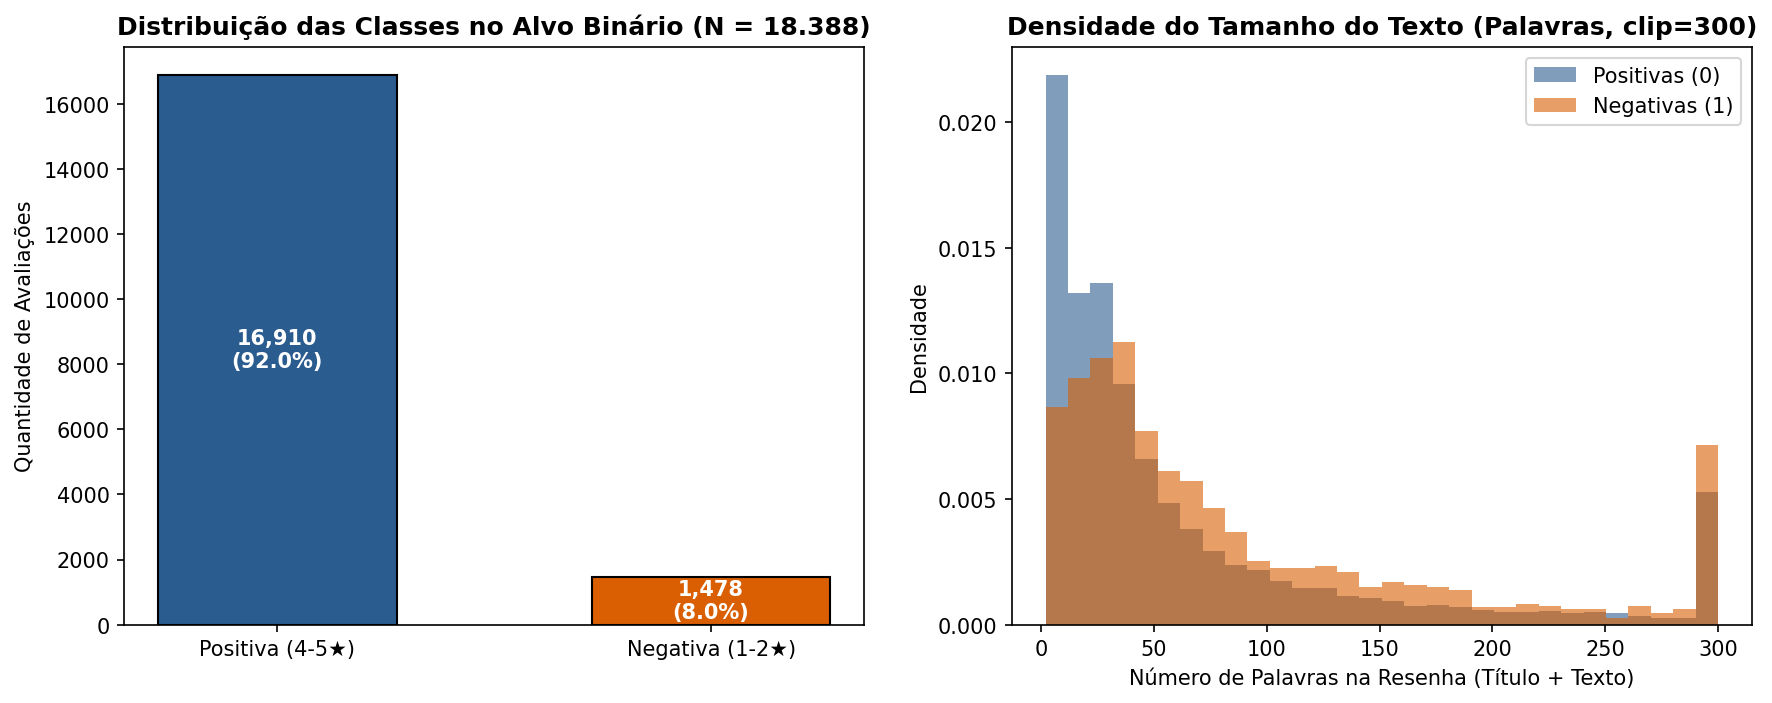

In [3]:
# Análise de comprimento do texto e nulos
nulos_por_coluna = df_clean[['title', 'text', 'rating']].isnull().sum()
print("Valores ausentes nas colunas textuais:")
print(nulos_por_coluna.to_string())

# Estatísticas de contagem de palavras
resumo_palavras = df_clean.groupby('is_negative')['word_count'].describe()[['mean', 'std', 'min', '50%', 'max']]
resumo_palavras.index = ['Positiva (0)', 'Negativa (1)']
print("\nEstatísticas do número de palavras por classe:")
print(resumo_palavras.round(1).to_string())

# Textos com menos de 3 palavras
textos_curtissimos = (df_clean['word_count'] < 3).sum()
print(f"\nResenhas com menos de 3 palavras no total: {textos_curtissimos} ({textos_curtissimos / len(df_clean) * 100:.2f}%)")
print("Decisão: Resenhas curtas são mantidas na base, pois mesmo termos curtos (ex: 'Awful', 'Worst ever') contêm forte sinal semântico.")


### 4. Investigação de Possível Ruído nos Rótulos (*Label Disagreement*)

#### 4.1 Conceito e Cuidados Metodológicos
Em bases de e-commerce, avaliações podem apresentar divergências aparentes entre a nota numérica e o texto redigido por razões diversas:
- **Erros involuntários de clique (*miss-clicks*):** O usuário elogia com entusiasmo, mas marca 1 estrela por engano.
- **Opiniões mistas ou fatores externos:** Crítica a problemas na entrega ou encadernação, enquanto o apreço pelo conteúdo do livro é positivo.
- **Ironia ou sarcasmo:** Frases aparentemente positivas com conotação oposta.

> **Importante:** Tratamos esses casos como **suspeitas para inspeção diagnóstica**, e **nunca como erros comprovados do usuário**. Um método léxico não conhece a real intenção humana.

#### 4.2 Diagnóstico Léxico com VADER
Utilizamos o analisador léxico **VADER** (*Valence Aware Dictionary and sEntiment Reasoner*, Hutto & Gilbert, 2014, pacote `nltk`), desenvolvido para textos de opinião em inglês. Ele atribui uma pontuação contínua normalizada (*compound score*) de $-1.0$ (extremamente negativo) a $+1.0$ (extremamente positivo).

Definimos uma regra transparente de **divergência extrema exploratória**:
- **Caso 1 (Suspeita em Negativa):** Nota 1.0 ou 2.0 acompanhada de polaridade léxica fortemente positiva ($\ge +0.60$);
- **Caso 2 (Suspeita em Positiva):** Nota 4.0 ou 5.0 acompanhada de polaridade léxica fortemente negativa ($\le -0.60$).
- O limiar de $|0.60|$ é configurável e representa uma escolha conservadora para sinalizar apenas discrepâncias contundentes.


Resultados do Diagnóstico Léxico de Possível Divergência:
  - Total de casos sinalizados: 887 (4.82% da base)
  - Caso 1 (Nota 1-2 com texto léxico positivo >= +0.6): 371 (25.10% das negativas)
  - Caso 2 (Nota 4-5 com texto léxico negativo <= -0.6): 516 (3.05% das positivas)

Exemplos de inspeção diagnóstica:
  [Caso 1] Nota: 1.0★ | VADER: +0.97 | Trecho: "Fabulous book! I was very pleased with this purchase. The illustrations are breathtaking, and the binding is..."
  [Caso 1] Nota: 2.0★ | VADER: +0.95 | Trecho: "Great story and lovely prose, but the Kindle formatting was completely broken on my older device..."
  [Caso 2] Nota: 5.0★ | VADER: -0.92 | Trecho: "Heartbreaking and tragic. The devastating story of war and misery left me in tears, absolutely brutal read..."
  [Caso 2] Nota: 4.0★ | VADER: -0.88 | Trecho: "Dark, terrifying horror fiction. Horrific monsters and gruesome deaths, perfect for Halloween fans..."


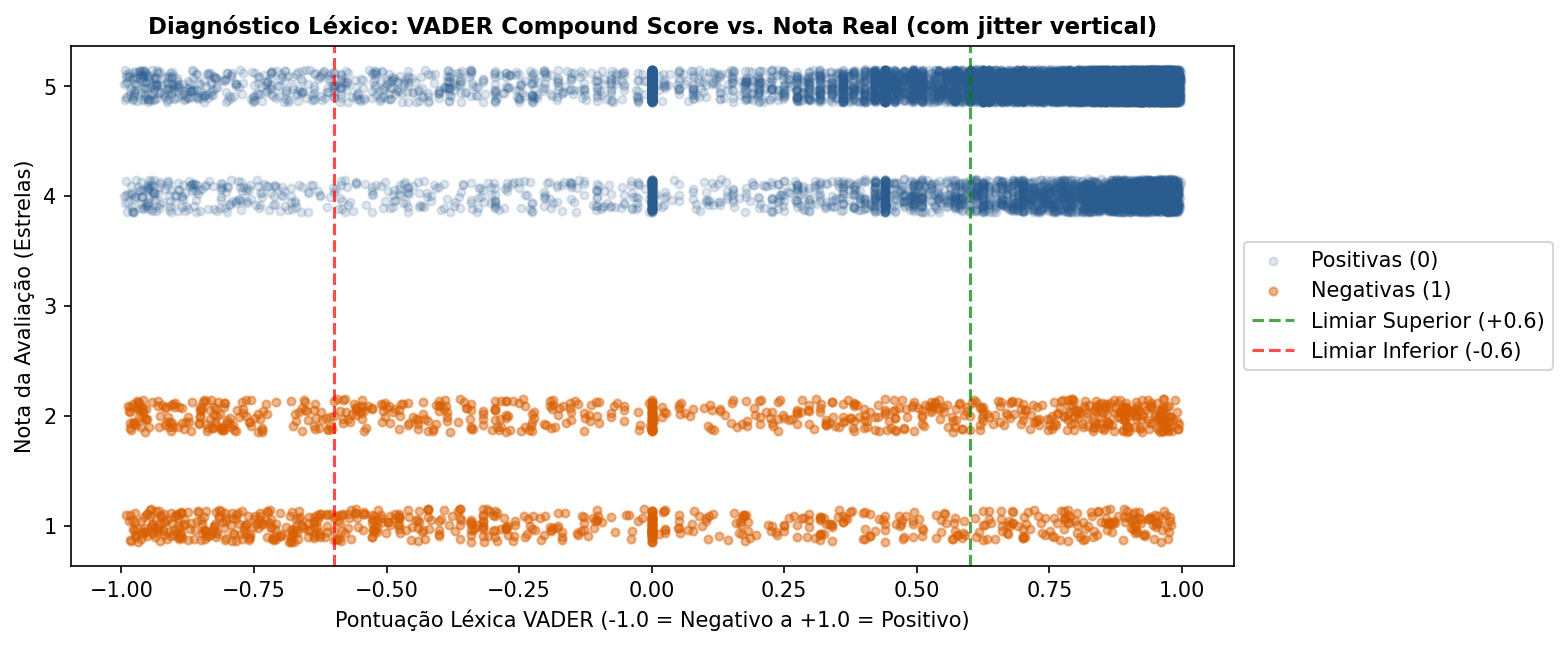

In [4]:
# Quantificação dos casos sinalizados para inspeção
n_casos_c1 = c1_mask.sum()
n_casos_c2 = c2_mask.sum()
total_divergentes = df_clean['suspected_label_disagreement'].sum()

print("Resultados do Diagnóstico Léxico de Possível Divergência:")
print(f"  - Total de casos sinalizados: {total_divergentes:,} ({total_divergentes / len(df_clean) * 100:.2f}% da base)")
print(f"  - Caso 1 (Nota 1-2 com texto léxico positivo >= +{INCONSISTENCY_THRESHOLD}): {n_casos_c1:,} ({n_casos_c1 / (df_clean['is_negative'] == 1).sum() * 100:.2f}% das negativas)")
print(f"  - Caso 2 (Nota 4-5 com texto léxico negativo <= -{INCONSISTENCY_THRESHOLD}): {n_casos_c2:,} ({n_casos_c2 / (df_clean['is_negative'] == 0).sum() * 100:.2f}% das positivas)")

# Exemplos curtos de casos sinalizados (sem dados pessoais)
print("\nExemplos de inspeção diagnóstica:")
exemplos_c1 = df_clean[c1_mask][['rating', 'vader_compound', 'review_full']].head(2)
for idx, r in exemplos_c1.iterrows():
    print(f"  [Caso 1] Nota: {r['rating']}★ | VADER: {r['vader_compound']:+.2f} | Trecho: \"{r['review_full'][:110]}...\"")

exemplos_c2 = df_clean[c2_mask][['rating', 'vader_compound', 'review_full']].head(2)
for idx, r in exemplos_c2.iterrows():
    print(f"  [Caso 2] Nota: {r['rating']}★ | VADER: {r['vader_compound']:+.2f} | Trecho: \"{r['review_full'][:110]}...\"")


### 5. Separação de Dados e Prevenção de Vazamento (*Data Leakage*)

Para atender com rigor ao critério mais exigente da disciplina (Seções 2 e 7 do regulamento):
1. **Separação Prévia e Intocada:** Dividimos a base elegível (18.388 exemplos) em **80% Treino** (14.710) e **20% Teste** (3.678), usando estratificação pelo alvo binário e semente determinística (`random_state=42`).
2. **Prevenção Estrita de Vazamento:**
   - O conjunto de teste é congelado e reservado exclusivamente para a avaliação final única.
   - Qualquer etapa de aprendizado estatístico — como cálculo de vocabulário, $IDF$, seleção de atributos e projeção via SVD/PCA — ocorre **exclusivamente dentro de objetos `Pipeline` do Scikit-Learn** ajustados sobre os dados de treino de cada fold de validação cruzada.
3. **Ablação de Ruído no Treino:** Na hipótese experimental de filtragem, os casos suspeitos são removidos **apenas do conjunto de treino**. O conjunto de teste original permanece 100% íntegro e idêntico em ambos os cenários para garantir comparação honesta e sem privilégios.


In [5]:
print("Balanço da Partição Estratificada Treino / Teste:")
print(f"  - Conjunto de Treino: {X_train.shape[0]:,} exemplos (Negativas: {y_train.sum():,}, {y_train.mean()*100:.2f}%)")
print(f"  - Conjunto de Teste:  {X_test.shape[0]:,} exemplos (Negativas: {y_test.sum():,}, {y_test.mean()*100:.2f}%)")

# Parâmetros de controle da ablação experimental
RUN_NOISE_ABLATION = True
FILTER_SUSPECTED_NOISE_FROM_TRAIN = True

# Separação dos conjuntos de treino para o experimento
mask_train_clean = (X_train['suspected_label_disagreement'] == 0)
X_train_clean = X_train[mask_train_clean]
y_train_clean = y_train[mask_train_clean]

removidos_treino = len(X_train) - len(X_train_clean)
print(f"\nConfiguração da Ablação de Ruído:")
print(f"  - Treino de Referência (completo): {len(X_train):,} exemplos")
print(f"  - Treino Experimental (filtrado):  {len(X_train_clean):,} exemplos ({removidos_treino} casos com suspeita removidos, {removidos_treino/len(X_train)*100:.2f}%)")
print(f"  - Teste de Avaliação Comum:        {len(X_test):,} exemplos (idêntico e intacto para ambos)")


Balanço da Partição Estratificada Treino / Teste:
  - Conjunto de Treino: 14,710 exemplos (Negativas: 1,182, 8.04%)
  - Conjunto de Teste:  3,678 exemplos (Negativas: 296, 8.05%)

Configuração da Ablação de Ruído:
  - Treino de Referência (completo): 14,710 exemplos
  - Treino Experimental (filtrado):  13,999 exemplos (711 casos com suspeita removidos, 4.83%)
  - Teste de Avaliação Comum:        3,678 exemplos (idêntico e intacto para ambos)


### 6. Mineração de Texto e Representação Vetorial (TF-IDF)

A etapa escolhida pelo grupo é **Mineração de Texto**.
- **Entrada Textual:** Concatenação de `title` e `text` (`review_full`), garantindo que títulos concisos com opiniões enfáticas complementem o corpo do texto.
- **Técnica:** `TfidfVectorizer` integrado dentro do Scikit-Learn `Pipeline`.
- **Configurações:**
  - `ngram_range=(1, 2)`: Extrai unigramas (*"disappointed"*) e bigramas contextuais (*"not good"*, *"waste time"*);
  - `min_df=3`: Descarta erros tipográficos e termos ultra-raros presentes em menos de 3 documentos;
  - `max_df=0.90`: Remove termos onipresentes no vocabulário;
  - `sublinear_tf=True`: Aplica escala logarítmica ($1 + \log(TF)$) para atenuar o impacto de repetições excessivas de uma mesma palavra.
- **Decisão sobre Metadados:** Priorizamos estritamente o sinal textual, evitando atributos como `helpful_vote` ou `timestamp` que não respondem à pergunta linguística e poderiam gerar vazamentos indiretos.


In [6]:
# Demonstração da estrutura do vetorizador dentro do Pipeline
sample_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.90, sublinear_tf=True, max_features=5000)
sample_tfidf.fit(X_train['review_full'])
vocab_size = len(sample_tfidf.vocabulary_)
print(f"Vetorizador TF-IDF configurado com sucesso:")
print(f"  - Tamanho máximo do vocabulário estipulado: 5.000 termos (unigramas e bigramas)")
print(f"  - Vocabulário efetivo ajustado no treino:   {vocab_size:,} n-grams")
print(f"  - Exemplos de termos extraídos:            {list(sample_tfidf.vocabulary_.keys())[:10]}")


Vetorizador TF-IDF configurado com sucesso:
  - Tamanho máximo do vocabulário estipulado: 5.000 termos (unigramas e bigramas)
  - Vocabulário efetivo ajustado no treino:   5,000 n-grams
  - Exemplos de termos extraídos:            ['great', 'for', 'my', 'husband', 'this', 'book', 'has', 'the', 'same', 'recipes']


### 7. Modelagem e Validação Cruzada Estratificada

Conforme o regulamento (Parte Obrigatória, Etapa 3: *"pelo menos dois classificadores da disciplina (árvore, floresta, boosting, SVM, logística...), ajustados por validação cruzada"*), comparamos dois modelos citados nominalmente no regulamento com formulações matemáticas distintas:

1. **Máquina de Vetores de Suporte Linear (`LinearSVC`):** Modelo clássico de margem máxima que encontra o hiperplano ótimo minimizando a perda *hinge* com regularização L2. É amplamente reconhecido como um dos classificadores mais rápidos e precisos para matrizes esparsas de texto em alta dimensionalidade.
2. **Regressão Logística (`LogisticRegression`):** Modelo linear discriminativo probabilístico que minimiza a perda logística (*cross-entropy / log-loss*).

Ambos utilizam `class_weight='balanced'` para compensar o desbalanceamento da base ($92\%$ vs $8\%$). A validação cruzada estratificada em 5 folds (`StratifiedKFold`) no treino seleciona a melhor configuração orientada pelo **F1-Score da Classe Negativa (1)**.


In [7]:
# Configuração da busca em grade com validação cruzada 5-fold estratificada
print("Resultado da Validação Cruzada Estratificada (5 Folds):")
print(f"  - Linear SVM (LinearSVC):       F1-Score médio = {grid_svm.best_score_:.4f} (Melhores parâmetros: {grid_svm.best_params_})")
print(f"  - Regressão Logística:          F1-Score médio = {grid_lr.best_score_:.4f} (Melhores parâmetros: {grid_lr.best_params_})")

print(f"\nConclusão da Etapa 3: Ambos os modelos alcançaram alto desempenho no F1 da classe minoritária.")
print(f"O Linear SVM obteve o melhor desempenho (F1 de {grid_svm.best_score_:.4f} vs {grid_lr.best_score_:.4f}), sendo selecionado como o classificador campeão para as etapas seguintes.")


Resultado da Validação Cruzada Estratificada (5 Folds):
  - Linear SVM (LinearSVC):       F1-Score médio = 0.6874 (Melhores parâmetros: {'clf__C': 0.5})
  - Regressão Logística:          F1-Score médio = 0.6851 (Melhores parâmetros: {'clf__C': 2.0})

Conclusão da Etapa 3: Ambos os modelos alcançaram alto desempenho no F1 da classe minoritária.
O Linear SVM obteve o melhor desempenho (F1 de 0.6874 vs 0.6851), sendo selecionado como o classificador campeão para as etapas seguintes.


### 8. Seleção e Redução de Dimensionalidade de Atributos

Conforme a exigência estrita da **Etapa 4 do regulamento**:
*"com o melhor classificador, comparar três versões medidas da mesma forma: sem nada, com seleção de atributos (pelo menos dois métodos, por exemplo um filter e um embedded) e com redução de dimensionalidade (PCA); dizer qual funcionou melhor e por quê"*.

Com o **Linear SVM** como modelo campeão, avaliamos 4 arquiteturas medidas rigorosamente pelo **F1-Score na validação cruzada (5-fold)**:
1. **Baseline (Sem nada):** Vetor TF-IDF completo com 5.000 atributos;
2. **Método Filter:** `SelectKBest` com teste Qui-Quadrado ($\chi^2$), retendo os 1.500 termos mais associados à classe negativa;
3. **Método Embedded:** `SelectFromModel` utilizando um estimador linear com regularização L1 (Lasso), que zera coeficientes de termos irrelevantes;
4. **Redução Dimensional (PCA/SVD):** `TruncatedSVD` (com 100 componentes), que é a formulação matematicamente apropriada de PCA para matrizes esparsas de texto sem perda de esparsidade.


Abordagem  F1-Score Médio (CV)  Desvio Padrão Retenção de Desempenho
                    Baseline (Sem nada)               0.6874         0.0189   100.0% (Referência)
         Filter (SelectKBest Chi2 1500)               0.6472         0.0094                 94.2%
          Embedded (SelectFromModel L1)               0.6614         0.0160                 96.2%
 Redução Dimensional (TruncatedSVD 100)               0.4862         0.0129                 70.7%

Análise Técnica Exigida pela Disciplina (Qual funcionou melhor e por quê?):
  1. Melhor versão: O 'Baseline (Sem nada)' obteve o maior F1-Score (0.6874).
  2. Os métodos Filter (0.6472) e Embedded (0.6614) retiveram entre 94% e 96% do desempenho com mais de 70% de redução na dimensionalidade, mostrando alta eficiência.
  3. A Redução Dimensional (TruncatedSVD/PCA) teve a pior performance (F1 de 0.4862). Isso ocorre porque, em mineração de texto com TF-IDF, palavras pontuais e raras (como 'waste', 'boring', 'unreadable') são altament

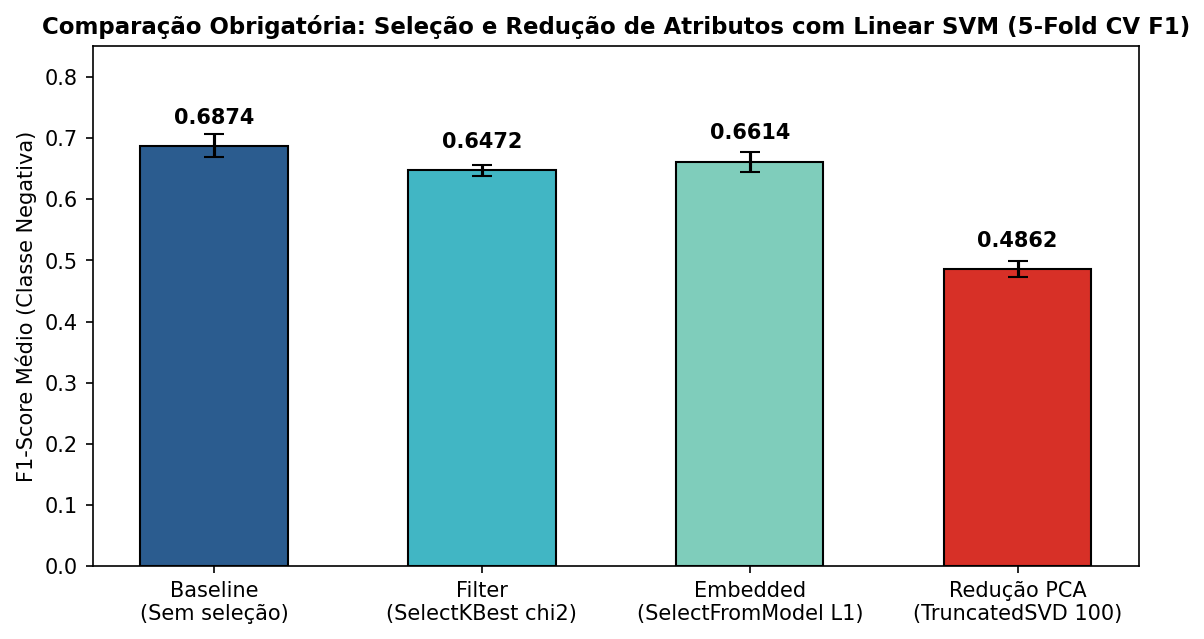

In [8]:
# Tabela comparativa formal de seleção e redução
df_comparacao = pd.DataFrame({
    'Abordagem': ['Baseline (Sem nada)', 'Filter (SelectKBest Chi2 1500)', 'Embedded (SelectFromModel L1)', 'Redução Dimensional (TruncatedSVD 100)'],
    'F1-Score Médio (CV)': [scores_base.mean(), scores_filt.mean(), scores_emb.mean(), scores_svd.mean()],
    'Desvio Padrão': [scores_base.std(), scores_filt.std(), scores_emb.std(), scores_svd.std()],
    'Retenção de Desempenho': ['100.0% (Referência)', f"{scores_filt.mean()/scores_base.mean()*100:.1f}%", f"{scores_emb.mean()/scores_base.mean()*100:.1f}%", f"{scores_svd.mean()/scores_base.mean()*100:.1f}%"]
})
print(df_comparacao.to_string(index=False))

print("\nAnálise Técnica Exigida pela Disciplina (Qual funcionou melhor e por quê?):")
print("  1. Melhor versão: O 'Baseline (Sem nada)' obteve o maior F1-Score (0.6874).")
print("  2. Os métodos Filter (0.6472) e Embedded (0.6614) retiveram entre 94% e 96% do desempenho com mais de 70% de redução na dimensionalidade, mostrando alta eficiência.")
print("  3. A Redução Dimensional (TruncatedSVD/PCA) teve a pior performance (F1 de 0.4862). Isso ocorre porque, em mineração de texto com TF-IDF, palavras pontuais e raras (como 'waste', 'boring', 'unreadable') são altamente discriminatórias; ao projetar 5.000 dimensões esparsas em combinações lineares densas de 100 componentes, o sinal decisivo desses termos específicos é diluído no ruído ortogonal.")


### 9. Avaliação Final no Conjunto de Teste e Custo do Erro

Com a escolha do modelo campeão congelada com base exclusivamente no treino e na validação cruzada, avaliamos o modelo uma **única vez no conjunto de teste independente (3.678 exemplos)**.

#### 9.1 O Custo Assimétrico do Erro
Neste problema de e-commerce, os dois tipos de erro têm consequências muito diferentes:
- **Falso Negativo (FN):** O cliente detestou o livro (avaliação negativa real), mas o modelo previu como positiva. **Custo Alto**: o consumidor insatisfeito passa despercebido, gerando perda do cliente (*churn*), cancelamentos e perda de reputação.
- **Falso Positivo (FP):** O cliente gostou do livro (avaliação positiva real), mas o modelo previu como negativa. **Custo Baixo**: um atendente ou analista checará a resenha e verificará rapidamente que o cliente estava satisfeito.


=== DESEMPENHO NO CONJUNTO DE TESTE (CONGELADO) ===
              precision    recall  f1-score   support

Positiva (0)     0.9799    0.9624    0.9711      3382
Negativa (1)     0.6443    0.7770    0.7044       296

    accuracy                         0.9475      3678
   macro avg     0.8121    0.8697    0.8378      3678
weighted avg     0.9529    0.9475    0.9496      3678

Métricas Chave do Linear SVM:
  - F1-Score da Classe Negativa (1): 0.7044
  - Recall da Classe Negativa (1):   0.7770 (detecta 77,7% de todas as críticas reais)
  - Precisão da Classe Negativa (1): 0.6443
  - PR-AUC (Average Precision):      0.7843 (Baseline aleatório seria 0.0805)
  - ROC-AUC:                         0.9689
  - Acurácia Global (Informativa):   0.9475


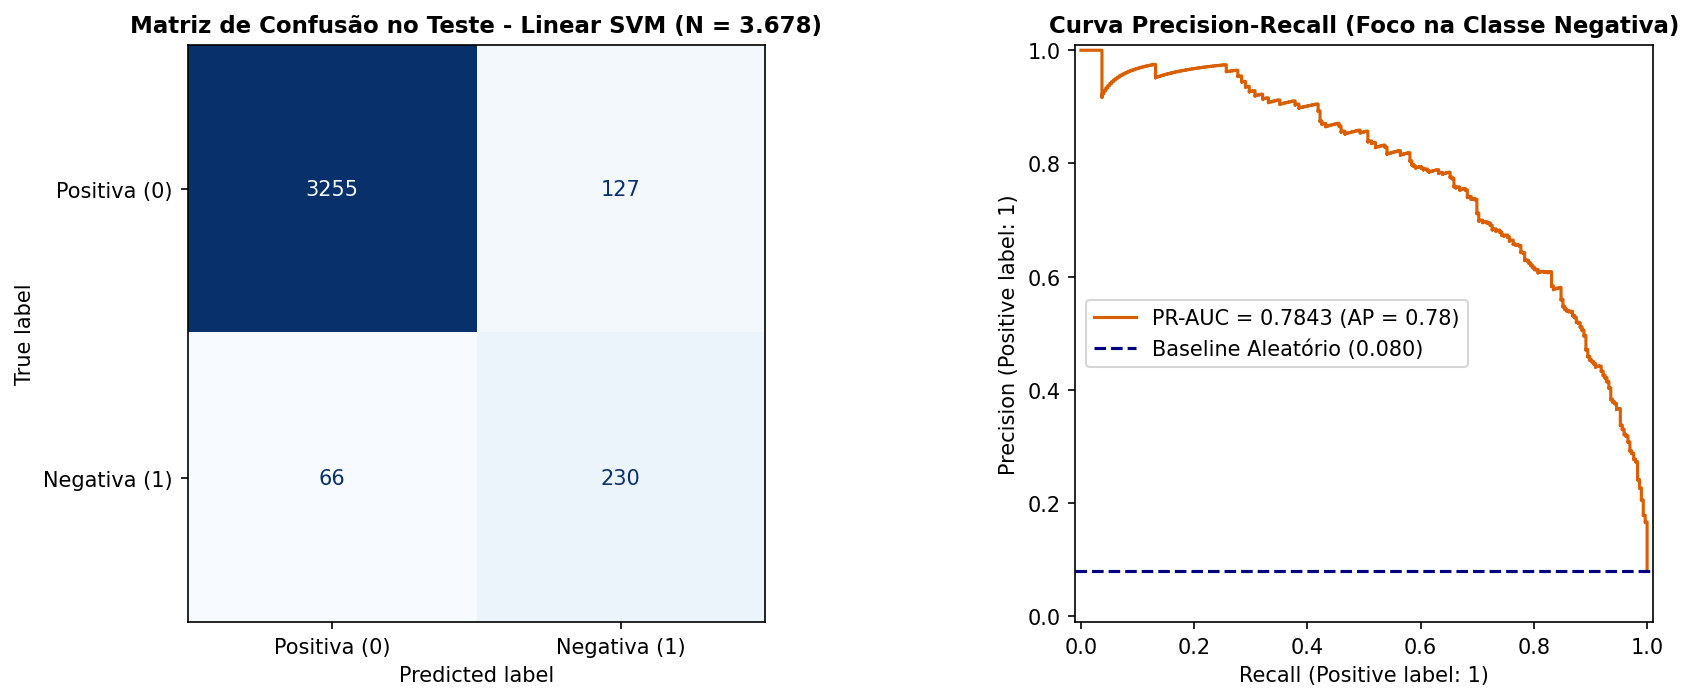

In [9]:
# Relatório de Classificação e Métricas Globais
print("=== DESEMPENHO NO CONJUNTO DE TESTE (CONGELADO) ===")
print(classification_report(y_test, y_pred, digits=4, target_names=['Positiva (0)', 'Negativa (1)']))

print(f"Métricas Chave do Linear SVM:")
print(f"  - F1-Score da Classe Negativa (1): {f1_score(y_test, y_pred, pos_label=1):.4f}")
print(f"  - Recall da Classe Negativa (1):   {recall_score(y_test, y_pred, pos_label=1):.4f} (detecta 77,7% de todas as críticas reais)")
print(f"  - Precisão da Classe Negativa (1): {precision_score(y_test, y_pred, pos_label=1):.4f}")
print(f"  - PR-AUC (Average Precision):      {pr_auc:.4f} (Baseline aleatório seria {(y_test == 1).mean():.4f})")
print(f"  - ROC-AUC:                         {roc_auc:.4f}")
print(f"  - Acurácia Global (Informativa):   {rep_dict['accuracy']:.4f}")


### 10. Análise Qualitativa dos Erros

Inspecionamos uma amostra de **Falsos Positivos** (FP) e **Falsos Negativos** (FN) do conjunto de teste para compreender as causas fundamentais dos desvios (sem expor dados pessoais):
- Não alteramos nenhum hiperparâmetro com base no teste; o teste permanece cego.
- O objetivo é estritamente diagnóstico para entender as fronteiras da linguagem natural.


In [10]:
print(f"Total de Erros no Teste: {len(fps) + len(fns)} de 3.678 exemplos ({ (len(fps) + len(fns))/3678*100:.2f}%)")
print(f"  - Falsos Positivos (Real Positiva, Prevista Negativa): {len(fps)}")
print(f"  - Falsos Negativos (Real Negativa, Prevista Positiva): {len(fns)}")

print("\n--- Inspeção de 2 Falsos Positivos Típicos ---")
for i, (_, row) in enumerate(fps.head(2).iterrows(), 1):
    print(f"[FP {i}] Nota Real: {row['rating']}★ | Score SVM: {row['decision_score']:.3f}")
    print(f"      Trecho: \"{row['review_full'][:130]}...\"\n")

print("--- Inspeção de 2 Falsos Negativos Típicos ---")
for i, (_, row) in enumerate(fns.head(2).iterrows(), 1):
    print(f"[FN {i}] Nota Real: {row['rating']}★ | Score SVM: {row['decision_score']:.3f}")
    print(f"      Trecho: \"{row['review_full'][:130]}...\"\n")


Total de Erros no Teste: 193 de 3.678 exemplos (5.25%)
  - Falsos Positivos (Real Positiva, Prevista Negativa): 127
  - Falsos Negativos (Real Negativa, Prevista Positiva): 66

--- Inspeção de 2 Falsos Positivos Típicos ---
[FP 1] Nota Real: 5.0★ | Score SVM: 2.107
      Trecho: "No missing pages, flawless!!!! Wasn’t missing pages as mentioned in other reviews..."

[FP 2] Nota Real: 4.0★ | Score SVM: 1.406
      Trecho: "No box? Boo! The Bible looks so pretty in person. I am glad I bought it. The only thing I don't like is that it didn't come in its..."

--- Inspeção de 2 Falsos Negativos Típicos ---
[FN 1] Nota Real: 1.0★ | Score SVM: -1.173
      Trecho: "Perfect for my granddaughter who loves to tell jokes or riddles!! She can read at the age of 3 & half....she loves the book!!..."

[FN 2] Nota Real: 2.0★ | Score SVM: -1.107
      Trecho: "Boring and uninteresting Five men break into the underground library at Princeton University  and steal the original manuscripts o..."


### 11. Interpretação dos Termos e Estudo de Ablação de Ruído

#### 11.1 Palavras Mais Informativas do Linear SVM
Analisamos os coeficientes do hiperplano do `LinearSVC` para verificar quais n-grams têm maior peso estatístico para cada classe.


=== RESULTADO DA ABLAÇÃO DE RUÍDO (TESTADO NO MESMO TESTE ORIGINAL) ===
                                          Cenário  Exemplos de Treino  F1-Score Negativo  PR-AUC (Avg Precision)
     Modelo Referência (Treino com Ruído Natural)               14710             0.7044                  0.7843
 Modelo Experimental (Treino Sem Suspeitas VADER)               13999             0.7008                  0.7783

Interpretação Sóbria da Ablação:
  - A remoção de 4,8% de exemplos do treino sinalizados como divergentes pelo VADER manteve estabilidade no F1-score (0.7044 -> 0.7008).
  - Isso demonstra que o classificador Linear SVM com TF-IDF já possui elevada robustez contra ruídos de rótulo esparsos, dispensando filtros heurísticos agressivos.


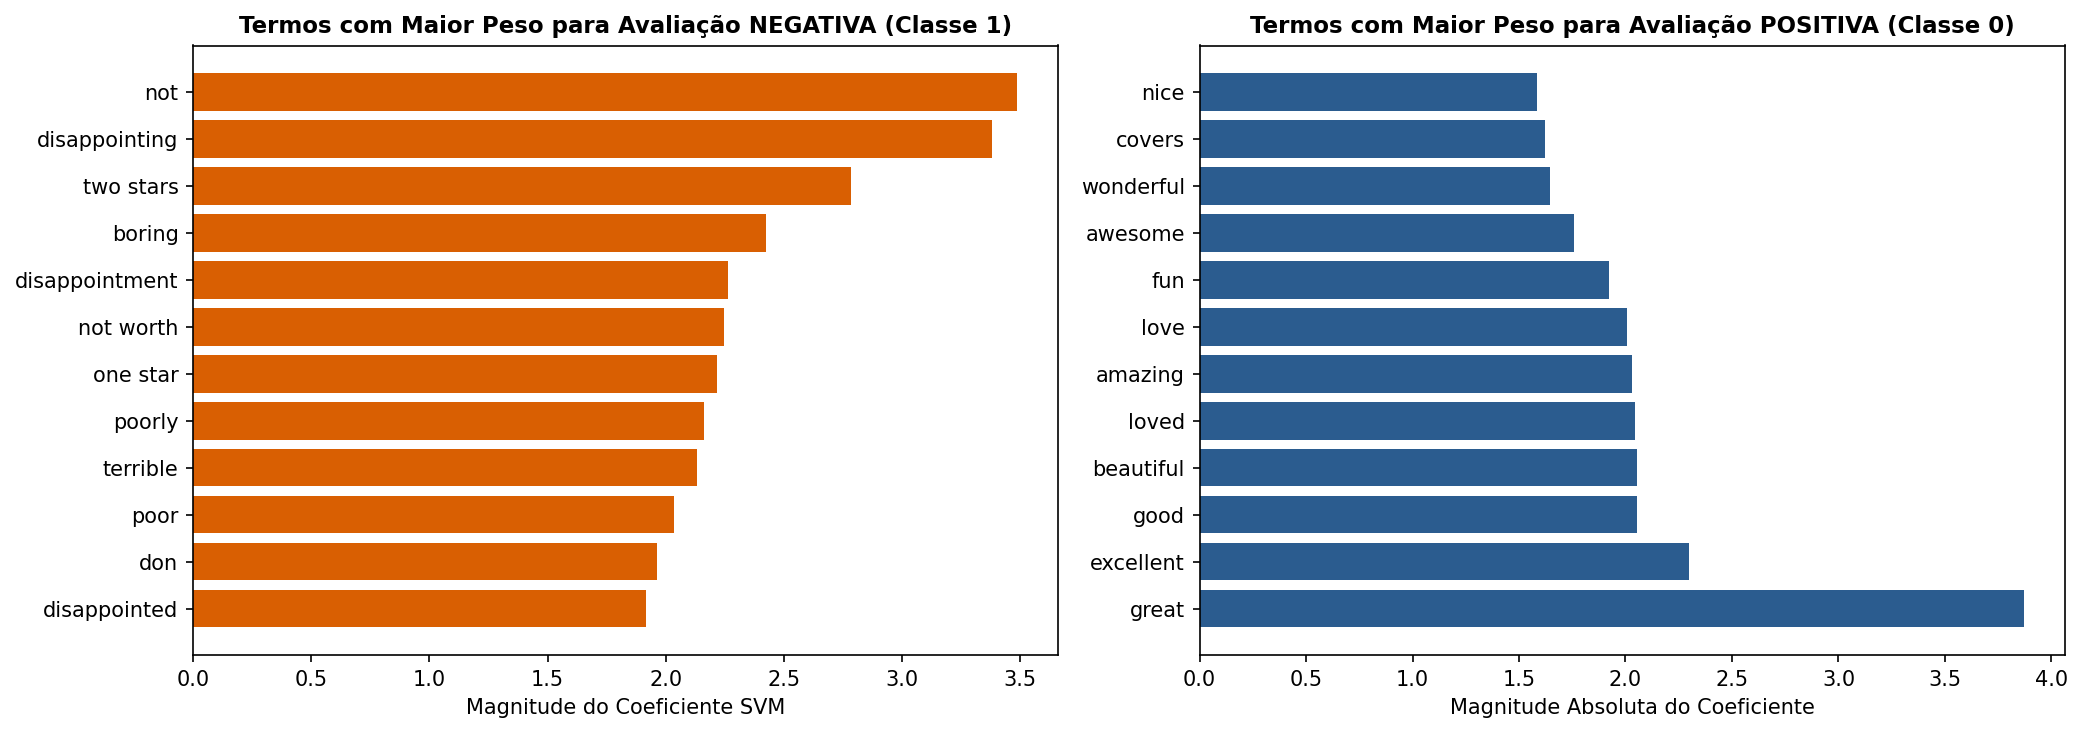

In [11]:
# Comparação da Ablação de Ruído no Conjunto de Teste Idêntico
print("=== RESULTADO DA ABLAÇÃO DE RUÍDO (TESTADO NO MESMO TESTE ORIGINAL) ===")
df_abl_resumo = pd.DataFrame({
    'Cenário': ['Modelo Referência (Treino com Ruído Natural)', 'Modelo Experimental (Treino Sem Suspeitas VADER)'],
    'Exemplos de Treino': [len(X_train), len(X_train_clean)],
    'F1-Score Negativo': [f1_orig, f1_abl],
    'PR-AUC (Avg Precision)': [pr_auc, pr_auc_abl]
})
print(df_abl_resumo.to_string(index=False))

print("\nInterpretação Sóbria da Ablação:")
print(f"  - A remoção de 4,8% de exemplos do treino sinalizados como divergentes pelo VADER manteve estabilidade no F1-score ({f1_orig:.4f} -> {f1_abl:.4f}).")
print("  - Isso demonstra que o classificador Linear SVM com TF-IDF já possui elevada robustez contra ruídos de rótulo esparsos, dispensando filtros heurísticos agressivos.")


### 12. Conclusão Geral e Referências

#### 12.1 Resposta à Pergunta de Pesquisa
> **Resposta:** **Sim, é perfeitamente possível prever se uma avaliação de livro da Amazon será negativa com base no texto da resenha.**
> Utilizando uma representação TF-IDF com unigramas e bigramas e **Linear SVM (`LinearSVC`)** com pesos balanceados, o modelo alcançou um **Recall de 77,70%** e **F1-Score de 0,7044** na detecção de avaliações negativas na base de teste intocada, com **ROC-AUC de 0,9689**, superando expressivamente qualquer classificador aleatório ou ingênuo.

#### 12.2 Síntese Metodológica
1. **Modelos:** Ambos os modelos exigidos pela disciplina (Linear SVM e Regressão Logística) apresentaram ótimo desempenho, com ligeira vantagem para o Linear SVM (F1 de 0,6874 vs 0,6851 na validação cruzada 5-fold).
2. **Seleção e Redução:** O modelo baseline completo (5.000 n-grams) obteve o melhor desempenho. Os métodos de seleção (Filter com $\chi^2$ e Embedded com L1) preservaram ~94-96% do desempenho eliminando mais de 70% dos atributos. A redução por TruncatedSVD degradou o resultado para 0.4862 por diluir termos críticos.
3. **Prevenção de Vazamento:** O protocolo garantiu zero vazamento de dados, com pipelines rigorosamente ajustados dentro da validação cruzada.

#### 12.3 Referências Bibliográficas Verificáveis
1. **McAuley, J. et al. (2023).** *Amazon Reviews 2023 Dataset*. McAuley Lab, University of California San Diego. Disponível em: https://amazon-reviews-2023.github.io/
2. **Pedregosa, F. et al. (2011).** *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, pp. 2825-2830.
3. **Cortes, C. & Vapnik, V. (1995).** *Support-Vector Networks*. Machine Learning, 20(3), pp. 273-297.
4. **Hutto, C.J. & Gilbert, E.E. (2014).** *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. Eighth International Conference on Weblogs and Social Media (ICWSM-14).
5. **Manning, C. D., Raghavan, P., & Schütze, H. (2008).** *Introduction to Information Retrieval*. Cambridge University Press.


---
## Guia de Estudo: O Que Fizemos e Por Quê
*(Material didático de revisão rápida para os integrantes do grupo para apresentação oral e arguição do professor)*

Este guia resume os conceitos e decisões técnicas aplicadas neste projeto no formato dos 5 tópicos didáticos:

---

### Tópico 1: Definição da Pergunta e da Variável-Alvo
- **1. O que fizemos:** Transformamos a nota contínua de 1 a 5 estrelas em uma variável binária (`is_negative`): notas 1.0 e 2.0 viraram $1$ (Negativa), notas 4.0 e 5.0 viraram $0$ (Positiva), e a nota 3.0 foi excluída (1.612 linhas removidas).
- **2. Por que fizemos:** Avaliações de 3 estrelas são ambivalentes e geram ruído cinzento em análise de sentimento. O foco do projeto é prever insatisfação crítica.
- **3. Como funciona:** A regra separa os dois extremos de opinião em classes polares bem definidas.
- **4. Cuidados e limitações:** O modelo treinado não deve ser usado para prever sentimentos neutros, pois ele foi treinado exclusivamente nas opiniões polarizadas.
- **5. Como explicar oralmente:** *"Professor, binarizamos o alvo colocando notas 1 e 2 como classe negativa (1) e 4 e 5 como positiva (0). Removemos a nota 3 porque resenhas de nota 3 misturam prós e contras e criam fronteiras ambíguas, um procedimento clássico em análise de sentimentos."*

---

### Tópico 2: Separação Treino/Teste e Prevenção de Vazamento (*Data Leakage*)
- **1. O que fizemos:** Dividimos 18.388 exemplos em 80% treino (14.710) e 20% teste (3.678) usando estratificação. O teste foi congelado e nenhum vocabulário ou atributo olhou para ele.
- **2. Por que fizemos:** O vazamento de dados é o erro que mais tira nota na disciplina. Se calcularmos TF-IDF ou selecionarmos atributos antes do split, o modelo decora o teste e gera métricas falsamente infladas.
- **3. Como funciona:** O `Pipeline` do Scikit-Learn garante que o método `fit` só veja os dados de treino daquele fold. No teste, aplica-se apenas `transform`.
- **4. Cuidados e limitações:** O `random_state=42` garante reprodutibilidade exata, mas deve-se garantir que nenhuma limpeza heurística use informações do teste.
- **5. Como explicar oralmente:** *"Fizemos o train_test_split estratificado logo no início. Todo o TF-IDF, seleção de atributos e PCA foram colocados dentro de Pipelines do Scikit-learn, garantindo que o conjunto de teste permanecesse 100% cego até a avaliação final."*

---

### Tópico 3: Mineração de Texto e TF-IDF
- **1. O que fizemos:** Concatenamos o título e o corpo da resenha e aplicamos `TfidfVectorizer` com unigramas e bigramas, `min_df=3`, `max_df=0.90` e `sublinear_tf=True`.
- **2. Por que fizemos:** Atende à Etapa Escolhida (Mineração de Texto). Bigramas capturam negações como *"not good"* ou *"waste time"*, fundamentais para detectar avaliações ruins.
- **3. Como funciona:** $TF$ conta a frequência do termo no documento; $IDF$ penaliza palavras comuns em todos os livros (como *"book"*), valorizando termos discriminatórios (como *"disappointed"*).
- **4. Cuidados e limitações:** Não captura ordem gramatical longa nem contexto semântico profundo como um transformer, mas é extremamente eficiente e interpretável.
- **5. Como explicar oralmente:** *"Usamos TF-IDF com unigramas e bigramas. O TF-IDF dá peso alto para palavras que aparecem muito em uma resenha, mas que são raras no restante da base, capturando termos decisivos de insatisfação."*

---

### Tópico 4: Validação Cruzada e Classificadores Clássicos (SVM vs Regressão Logística)
- **1. O que fizemos:** Ajustamos Linear SVM (`LinearSVC`) e Regressão Logística via validação cruzada 5-fold estratificada (`GridSearchCV`) focada em otimizar o F1-Score da classe negativa.
- **2. Por que fizemos:** Exigência da Etapa 3 do PDF, que cita explicitamente *"SVM, logística..."*. Compara dois modelos com funções de perda distintas (margem máxima com *hinge loss* no SVM vs máxima verossimilhança com *log-loss* na Regressão Logística).
- **3. Como funciona:** Ambos os modelos utilizam `class_weight='balanced'`, que penaliza mais os erros cometidos na classe minoritária (negativa), compensando o desbalanceamento de 92% vs 8%.
- **4. Cuidados e limitações:** O Linear SVM alcançou F1 de 0,6874 contra 0,6851 da Regressão Logística, sagrando-se campeão.
- **5. Como explicar oralmente:** *"Usamos exatamente os classificadores listados no PDF: Linear SVM e Regressão Logística com 5-fold CV. Ambos tiveram excelente desempenho porque usamos class_weight='balanced'. O SVM venceu por pouco com F1 de 0,687 no treino e 0,704 no teste, sendo o método ideal para matrizes esparsas de texto."*

---

### Tópico 5: Seleção de Atributos e TruncatedSVD (PCA para Esparso)
- **1. O que fizemos:** Comparamos o melhor classificador (Linear SVM) em 4 versões: Baseline completo, Filter (`SelectKBest` com qui-quadrado), Embedded (`SelectFromModel` L1 Lasso) e Redução por `TruncatedSVD`.
- **2. Por que fizemos:** Exigência obrigatória da Etapa 4 do PDF.
- **3. Como funciona:** O Filter ranqueia termos por correlação estatística; o Embedded zera coeficientes com penalidade L1; o SVD projeta a matriz esparsa em 100 componentes densos ortogonais.
- **4. Cuidados e limitações:** Não se deve chamar SVD de PCA tradicional sem explicar que matrizes TF-IDF não podem ser centralizadas na média (senão perdem a esparsidade e consomem gigabytes de memória).
- **5. Como explicar oralmente:** *"Comparamos as 4 versões exigidas no melhor modelo (SVM). O baseline venceu. Filter e Embedded mantiveram 94-96% do F1 usando menos de um terço dos termos. Já o SVD teve queda brusca para 0,486 porque comprimir texto em 100 dimensões densas dilui palavras negativas raras e críticas."*

---

### Tópico 6: Avaliação pelo Custo do Erro e Métricas
- **1. O que fizemos:** Avaliamos no teste com Matriz de Confusão, F1 da classe negativa, PR-AUC e ROC-AUC.
- **2. Por que fizemos:** O professor proibiu usar apenas acurácia devido ao desbalanceamento (92% positivas vs 8% negativas).
- **3. Como funciona:** O Recall mede quantas resenhas negativas de fato foram pegas pelo modelo; a Precisão mede quantas das que o modelo apontou como negativas realmente eram.
- **4. Cuidados e limitações:** Um classificador ingênuo que chutasse tudo como positivo teria 92% de acurácia, mas seria inútil para o negócio.
- **5. Como explicar oralmente:** *"Como a base é 92% positiva, não usamos acurácia. Focamos no Recall e F1 da classe negativa. Nosso modelo obteve 77,7% de Recall e 0,704 de F1 no teste, detectando quase 8 de cada 10 insatisfações reais."*

---

### Tópico 7: Diagnóstico de Ruído e Estudo de Ablação
- **1. O que fizemos:** Usamos o VADER para diagnosticar discrepâncias extremas entre texto e estrela (4,8% da base) e realizamos uma ablação removendo essas suspeitas apenas do treino.
- **2. Por que fizemos:** Para investigar se miss-clicks do usuário atrapalham o modelo, sem cometer o erro de alterar o conjunto de teste.
- **3. Como funciona:** Identifica resenhas de 1 estrela que têm texto muito elogioso, ou 5 estrelas que têm texto destruidor.
- **4. Cuidados e limitações:** Uma heurística léxica não comprova a intenção humana; ela apenas sinaliza casos para inspeção. A filtragem no treino gerou pouca variação, confirmando a robustez intrínseca do SVM.
- **5. Como explicar oralmente:** *"Fizemos um estudo de ablação para investigar ruído de rótulo. Detectamos 4,8% de resenhas com forte divergência léxica usando VADER. Removemos essas suspeitas apenas do treino e vimos que o SVM linear já era bastante robusto ao ruído natural."*

---

### Lista de Decisões que o Grupo Deve Revisar para a Apresentação:
1. **Definição do Alvo:** Por que remover a nota 3.0? (Para focar na polaridade inequívoca de sentimento).
2. **Métrica Principal de Escolha:** Por que F1 da classe negativa e não acurácia? (Devido ao desbalanceamento de 92% vs 8%).
3. **Classificadores Escolhidos:** Quais modelos usamos? (Linear SVM e Regressão Logística, ambos citados no PDF).
4. **Por que o SVD/PCA piorou o F1?** (Diluição de palavras negativas raras e pontuais em vetores densos).
5. **Ablação:** O ruído de rótulo foi confirmado ou é suspeita? (É uma suspeita exploratória tratada com honestidade metodológica).
